In [1]:
import torch
import os
import torchvision
from torchvision.transforms import v2
from torchvision import datasets
from pathlib import Path
from torch.utils.data import DataLoader
import torchvision.models as models
from tqdm.auto import tqdm
import torchinfo
from timeit import default_timer as timer
from torchinfo import summary
from typing import Dict, List
import matplotlib.pyplot as plt
import mlxtend
import torchmetrics
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix
import requests


c:\Users\Fidel S\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(size=(224, 224), antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.TrivialAugmentWide(num_magnitude_bins=20),
    v2.ToImage(), 
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
test_transform = v2.Compose([
    v2.Resize(size=(224, 224)),
    v2.CenterCrop(224),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [3]:
test_dir = Path("Data/test")
train_dir = Path("Data/train")

In [4]:
%cd ..

c:\Users\Fidel S\OneDrive\Desktop\OneAlpha\OneAlpha


In [5]:
train_data = datasets.ImageFolder(root=train_dir, transform=train_transform, target_transform=None)
test_data = datasets.ImageFolder(root=test_dir, transform=test_transform)

In [6]:
BATCH_SIZE = 8

train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              num_workers=4,
                              shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             num_workers=4,
                             shuffle=False,
                             )

In [7]:
weights = models.ResNet18_Weights.DEFAULT
model_1 = models.resnet18(weights=weights)

In [8]:
summary(model=model_1,
        input_size=(1,3,224,224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 1000]                 --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [10]:
def train_step(model: torch.nn.Module,
          loss_fn: torch.nn.Module,
          optimizer: torch.optim.Optimizer,
          X,
          y,
          device=None):
    model.train()

    train_loss, train_acc = 0,0

    X,y = X.to(device), y.to(device)

    y_pred = model(X)

    loss = loss_fn(y_pred, y)
    train_loss = loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    y_pred_class = torch.argmax(y_pred, dim=1)
    train_acc = (y_pred_class == y).sum().item()/len(y_pred)

    return train_loss, train_acc


In [11]:
def test_step(model: torch.nn.Module,
         loss_fn: torch.nn.Module,
         X,
         y,
         device=None):
    model.eval()

    test_loss, test_acc = 0,0

    with torch.inference_mode():
        X,y = X.to(device), y.to(device)

        y_pred = model(X)

        loss = loss_fn(y_pred, y)
        test_loss = loss.item()

        y_pred_class = torch.argmax(y_pred, dim=1)
        test_acc = (y_pred_class == y).sum().item()/len(y_pred)
        
    return test_loss, test_acc

In [12]:
MODEL_PATH = Path("Models")
MODEL_NAME = "restnet18_1"
MODEL_SAVE_PATH = MODEL_PATH/MODEL_NAME

In [13]:
def train(model: torch.nn.Module,
          loss_fn: torch.nn.Module,
          test_dataloader: torch.utils.data.DataLoader,
          train_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          epochs: int = 5,
          device=None):
    
    results = {"test_loss": [],
               "test_acc": [],
               "train_loss": [],
               "train_acc": [],
               "train_epoch_loss": [],
               "test_epoch_loss": [],
               "train_epoch_acc": [],
               "test_epoch_acc": []}
    
    for epoch in tqdm(range(epochs)):

        train_loss, train_acc = 0,0
        test_loss, test_acc = 0,0
        train_epoch_loss, train_epoch_acc = 0,0
        test_epoch_loss, test_epoch_acc = 0,0

        for batch, (X,y) in enumerate(train_dataloader):

            train_loss, train_acc = train_step(model=model,
                                               loss_fn=loss_fn,
                                               optimizer=optimizer,
                                               X=X,
                                               y=y,
                                               device=device)
            if batch != len(train_dataloader)-1:
                results["train_loss"].append(train_loss)
                results["train_acc"].append(train_acc)
                train_epoch_loss += train_loss
                train_epoch_acc += train_acc
        
        for batch, (X,y) in enumerate(test_dataloader):

            test_loss, test_acc = test_step(model=model,
                                            loss_fn=loss_fn,
                                            X=X,
                                            y=y,
                                            device=device)
            if batch != len(test_dataloader)-1:
                results["test_loss"].append(test_loss)
                results["test_acc"].append(test_acc)
                test_epoch_loss += test_loss
                test_epoch_acc += test_acc

        train_epoch_loss = train_epoch_loss/len(train_dataloader)
        test_epoch_loss = test_epoch_loss/len(test_dataloader)
        train_epoch_acc = train_epoch_acc/len(train_dataloader)
        test_epoch_acc = test_epoch_acc/len(test_dataloader)

        results["test_epoch_loss"].append(test_epoch_loss)
        results["test_epoch_acc"].append(test_epoch_acc)
        results["train_epoch_loss"].append(train_epoch_loss)
        results["train_epoch_acc"].append(train_epoch_acc)
        
        torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)
        
        print(f"Epoch: {epoch+1} | train_loss: {train_epoch_loss:.4f} | train_acc: {train_epoch_acc:.4f} | test_loss: {test_epoch_loss:.4f} | test_acc: {test_epoch_acc:.4f}")

        
    return results

In [14]:
loaded_model = model_1
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [15]:
EPOCHS = 10

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.00001)

start_time = timer()

model_1_results = train(loss_fn = loss_fn,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader,
                        epochs = EPOCHS,
                        device=device,
                        model=loaded_model)

end_time = timer()

print(f"Total training time: {end_time-start_time:.3f} seconds")

 10%|█         | 1/10 [14:38<2:11:43, 878.16s/it]

Epoch: 1 | train_loss: 2.0949 | train_acc: 0.4858 | test_loss: 1.2844 | test_acc: 0.6558


 20%|██        | 2/10 [29:45<1:59:20, 895.09s/it]

Epoch: 2 | train_loss: 2.0836 | train_acc: 0.4868 | test_loss: 1.2812 | test_acc: 0.6600


 30%|███       | 3/10 [44:35<1:44:11, 893.10s/it]

Epoch: 3 | train_loss: 2.0858 | train_acc: 0.4887 | test_loss: 1.2700 | test_acc: 0.6617


 40%|████      | 4/10 [59:15<1:28:46, 887.71s/it]

Epoch: 4 | train_loss: 2.0805 | train_acc: 0.4896 | test_loss: 1.2710 | test_acc: 0.6594


 50%|█████     | 5/10 [1:14:04<1:14:01, 888.28s/it]

Epoch: 5 | train_loss: 2.0790 | train_acc: 0.4896 | test_loss: 1.2671 | test_acc: 0.6610


 60%|██████    | 6/10 [1:28:07<58:11, 872.91s/it]  

Epoch: 6 | train_loss: 2.0696 | train_acc: 0.4912 | test_loss: 1.2683 | test_acc: 0.6612


 70%|███████   | 7/10 [1:41:24<42:23, 847.95s/it]

Epoch: 7 | train_loss: 2.0764 | train_acc: 0.4908 | test_loss: 1.2709 | test_acc: 0.6625


 80%|████████  | 8/10 [1:53:53<27:13, 816.61s/it]

Epoch: 8 | train_loss: 2.0771 | train_acc: 0.4890 | test_loss: 1.2724 | test_acc: 0.6607


 90%|█████████ | 9/10 [2:08:24<13:53, 833.66s/it]

Epoch: 9 | train_loss: 2.0721 | train_acc: 0.4911 | test_loss: 1.2627 | test_acc: 0.6629


100%|██████████| 10/10 [2:23:28<00:00, 860.82s/it]

Epoch: 10 | train_loss: 2.0761 | train_acc: 0.4907 | test_loss: 1.2730 | test_acc: 0.6620
Total training time: 8608.199 seconds


In [39]:
loaded_model = model_1
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [62]:
def plot_loss_curves(results: Dict[str, List[float]]):
    train_loss = results["train_epoch_loss"]
    test_loss = results["test_epoch_loss"]
    train_acc = results["train_epoch_acc"]
    test_acc = results["test_epoch_acc"]

    test_batch = range(len(results["test_epoch_loss"]))
    train_batch = range(len(results["train_epoch_loss"]))

    plt.figure(figsize=(15,7))

    plt.subplot(1,2,1)
    plt.plot(train_batch, train_loss, label="train_loss")
    plt.plot(test_batch, test_loss, label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(train_batch, train_acc, label="train_accuracy")
    plt.plot(test_batch, test_acc, label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

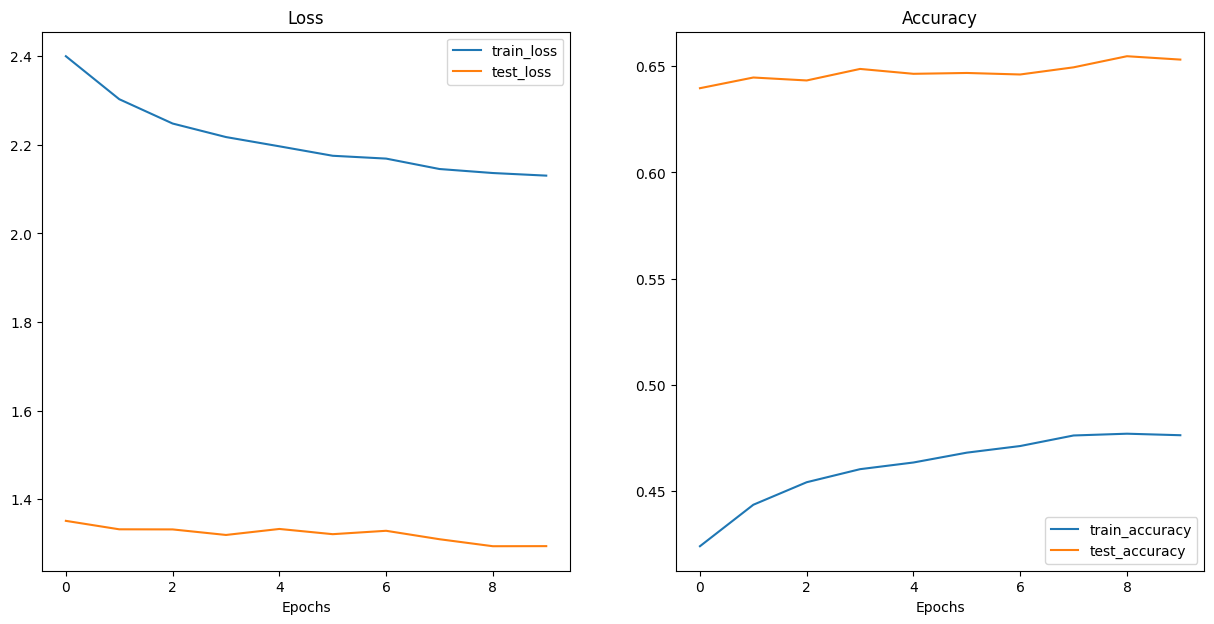

In [63]:
plot_loss_curves(model_1_results)

In [45]:
loaded_model.eval()

y_preds = []
y_pred = 0
test_acc = 0
with torch.inference_mode():
    for X,y in tqdm(test_dataloader):
        X,y = X.to(device), y.to(device)

        y_pred = loaded_model(X)

        y_pred_class = torch.argmax(y_pred, dim=1)
        y_preds.append(y_pred_class.cpu())
        test_acc += (y_pred_class == y).sum().item()
test_acc = test_acc/len(test_dataloader.dataset)

100%|██████████| 3157/3157 [03:11<00:00, 16.50it/s]


In [46]:
test_acc

0.6536237623762376

In [44]:
y_pred_tensor = torch.cat(y_preds)
class_names = train_data.classes
confmat = ConfusionMatrix(num_classes=101, task="multiclass")
confmat_tensor = confmat(preds=y_pred_tensor, target=torch.tensor(test_data.targets))
fig, ax = plot_confusion_matrix(conf_mat=confmat_tensor.numpy(),
                                class_names=class_names,
                                figsize=(100,100))

In [122]:
custom_image_path = Path("custom samples/pizza.jpg")

custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)/255
print(f"custom_image_unit8.shape: {custom_image.shape}")
print(f"custom_image_unit8.dtype: {custom_image.dtype}")

custom_image_unit8.shape: torch.Size([3, 800, 1200])
custom_image_unit8.dtype: torch.float32


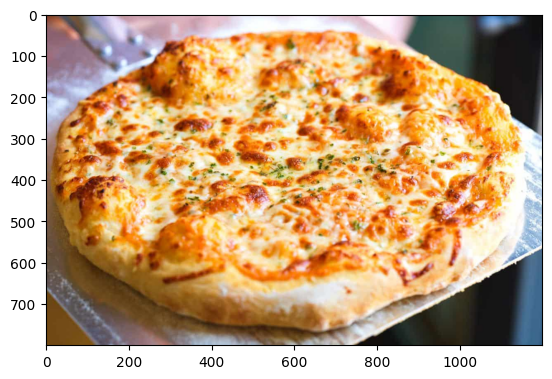

In [123]:
plt.imshow(custom_image.permute(1,2,0))

In [124]:
custom_transform = v2.Compose([
    v2.Resize(size=(224, 224), antialias=True),
    v2.CenterCrop(224), 
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [125]:
custom_image_transformed = custom_transform(custom_image)
custom_image_transformed.shape

torch.Size([3, 224, 224])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8661488..2.640001].


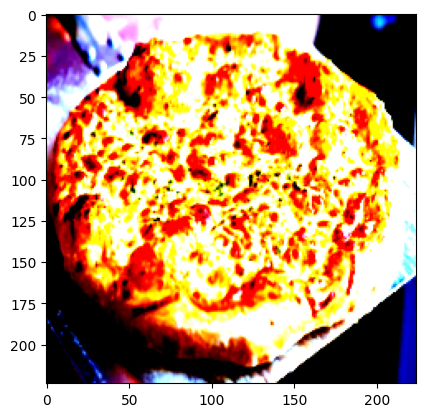

In [126]:
plt.imshow(custom_image_transformed.permute(1,2,0))

In [133]:
loaded_model.eval()
with torch.inference_mode():
    pred = loaded_model(custom_image_transformed.unsqueeze(0).to(device))
    ##pred = torch.argmax(loaded_model(custom_image_transformed.unsqueeze(0).to(device)), dim=1).cpu()
pred
##pred

tensor([[-17.7886, -26.4313, -25.4371, -30.9617, -24.5858, -31.6128, -20.1986,
         -25.6486, -23.6088, -22.3980, -19.7067, -27.9073, -21.9931, -27.4154,
         -22.2099, -27.1898, -23.8947, -22.3791, -22.2131, -22.0604, -27.2366,
         -28.0033, -26.0028, -22.3911, -21.3184, -24.6024, -23.0064, -21.4899,
         -19.2920, -21.8544, -24.0215, -15.3496, -23.8299, -33.7326, -18.7369,
         -20.5644, -20.2085, -27.4951, -25.2248, -24.6914, -28.5479, -19.2038,
         -17.5134, -25.9401, -25.6464, -27.9856, -14.0391, -21.5745, -29.3855,
         -15.8472, -19.6168, -28.9001, -20.9389, -21.3319, -28.4923, -21.2812,
         -19.8531, -18.0834, -26.7361, -20.3158, -23.2448, -20.4862, -17.8164,
         -23.5532, -33.2413, -26.0360, -26.2778, -17.8814, -23.7939, -32.2845,
         -24.2480, -24.4159, -17.1357, -26.3756, -29.6268, -33.1548, -14.3606,
         -23.5282, -24.2871, -28.8500, -21.3655, -26.9934, -23.4865, -28.0452,
         -24.3198, -25.0191, -30.0517, -22.7645, -30

In [128]:
class_names = train_data.classes
class_names[pred.item()]

'garlic_bread'